In [1]:
library(dplyr)
library(Seurat)
library(ggplot2)
library(reshape2)
library(tidyr)
library(pheatmap)
library(tibble)
library(ggrastr)
'%!in%' <- function(x,y)!('%in%'(x,y))
options(repr.plot.width = 12, repr.plot.height = 12)
options(future.globals.maxSize= 50*1024*1024^2)
resolve_save <- function(plot, path){
    ggsave(path, 
           plot = plot, 
           device = cairo_pdf, 
           width = 12, 
           height = 12, 
           units = "in", 
           dpi = 300, 
           bg = "transparent"
          )
}
setwd("/cluster/work/nme/data/coester/Project_8plex_tracing/Paper_figures_spatial")


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union


Loading required package: SeuratObject

Loading required package: sp


Attaching package: ‘SeuratObject’


The following objects are masked from ‘package:base’:

    intersect, t



Attaching package: ‘tidyr’


The following object is masked from ‘package:reshape2’:

    smiths




In [2]:
godsnot_102 <- c(
  "#FFFF00", "#1CE6FF", "#FF34FF", "#FF4A46", "#008941", "#006FA6", "#A30059",
  "#FFDBE5", "#7A4900", "#0000A6", "#63FFAC", "#B79762", "#004D43", "#8FB0FF",
  "#997D87", "#5A0007", "#809693", "#FEFFE6", "#1B4400", "#4FC601", "#3B5DFF",
  "#4A3B53", "#FF2F80", "#61615A", "#BA0900", "#6B7900", "#00C2A0", "#FFAA92",
  "#FF90C9", "#B903AA", "#D16100", "#DDEFFF", "#000035", "#7B4F4B", "#A1C299",
  "#300018", "#0AA6D8", "#013349", "#00846F", "#372101", "#FFB500", "#C2FFED",
  "#A079BF", "#CC0744", "#C0B9B2", "#C2FF99", "#001E09", "#00489C", "#6F0062",
  "#0CBD66", "#EEC3FF", "#456D75", "#B77B68", "#7A87A1", "#788D66", "#885578",
  "#FAD09F", "#FF8A9A", "#D157A0", "#BEC459", "#456648", "#0086ED", "#886F4C",
  "#34362D", "#B4A8BD", "#00A6AA", "#452C2C", "#636375", "#A3C8C9", "#FF913F",
  "#938A81", "#575329", "#00FECF", "#B05B6F", "#8CD0FF", "#3B9700", "#04F757",
  "#C8A1A1", "#1E6E00", "#7900D7", "#A77500", "#6367A9", "#A05837", "#6B002C",
  "#772600", "#D790FF", "#9B9700", "#549E79", "#FFF69F", "#201625", "#72418F",
  "#BC23FF", "#99ADC0", "#3A2465", "#922329", "#5B4534", "#FDE8DC", "#404E55",
  "#0089A3", "#CB7E98", "#A4E804", "#324E72", "#6A3A4C", "#83AB58", "#001C1E",
  "#D1F7CE", "#004B28", "#C8D0F6", "#A3A489", "#806C66", "#222800", "#BF5650",
  "#E83000", "#66796D", "#DA007C", "#FF1A59", "#8ADBB4", "#1E0200", "#5B4E51",
  "#C895C5", "#320033", "#FF6832", "#66E1D3", "#CFCDAC", "#D0AC94", "#7ED379",
  "#012C58"
)

cells_detailed <- c('00_Hmcn2_Gpr149', '01_Undefined', '02_Fezf1_Lama1', '03_Rai14_Acvr1c',
       '04_Crnde_Lmx1a', '05_Qrfpr_Pdzrn3', '06_Tbx3_Npy1r', '07_Nfib_Six3',
       '08_Lef1_Rspo2', '09_Nfia_Ccbe1', '10_Npy_Agrp', '11_Tafa4_Kank4',
       '12_Ntng2_Onecut1', '13_Pth2r_Otp', '14_Lhx1_Th', '15_Onecut1_Slc32a1',
       '16_Gal_Sox6', '17_Dkk2_Ebf3', '18_Ust_Bcl11b', '19_Bace2_Tspan18',
       '20_Tmem114_Npsr1', '21_Bnc2_Glp1r', '22_Crabp1_Vgll3', '23_Ust_Nkd2',
       '24_Nts_Ecel1', '25_Nxph4_Ebf3', '26_Dach2_Npsr1', '27_Lmx1a_Ttc6',
       '28_Kiss1_Slc38a3', '29_Dnah11_Pth2r', '30_Trh_Sim1', '31_Lhx9_Npvf',
       '32_Gucy2c_Ttc6', '33_Chat_Ghrh', '34_Pla2r1_Sim1', '35_Lhx9_Zic1',
       '36_Ebf2_Crhbp', '37_Qrfp_Qrfprl', '38_Hdc_Prph', '39_Nfib_Nfia',
       '40_Gpr50_Tac2', '41_Otx1_Zic1', '42_Foxb1_Myo5b', 'Astrocyte',
       'Endothelial_cell', 'Ependymal_cell', 'Epithelial-like_cell',
       'Microglia', 'OPC', 'Oligodendrocyte', 'Pericyte', 'Pituicyte',
       'Pituitary_Crhr1', 'Pituitary_Gnrhr', 'Pituitary_Mtnr1a',
       'Pituitary_Pappa2', 'Pituitary_Pax7', 'Pituitary_Rxfp1', 'Schwann_cell',
       'Tanycyte', 'Undefined', 'VLMC', "no_label")

colors_detailed <- c('#ffff00', '#1ce6ff', '#ff34ff', '#ff4a46', 
                      '#008941', '#006fa6', '#a30059', '#ffdbe5', 
                      '#7a4900', '#0000a6', '#63ffac', '#b79762', 
                      '#004d43', '#8fb0ff', '#997d87', '#5a0007', 
                      '#809693', '#6a3a4c', '#1b4400', '#4fc601', 
                      '#3b5dff', '#4a3b53', '#ff2f80', '#61615a', 
                      '#ba0900', '#6b7900', '#00c2a0', '#ffaa92', 
                      '#ff90c9', '#b903aa', '#d16100', '#ddefff', 
                      '#000035', '#7b4f4b', '#a1c299', '#300018', 
                      '#0aa6d8', '#013349', '#00846f', '#372101', 
                      '#ffb500', '#c2ffed', '#a079bf', '#cc0744', 
                      '#c0b9b2', '#c2ff99', '#001e09', '#00489c', 
                      '#6f0062', '#0cbd66', '#eec3ff', '#456d75', 
                      '#b77b68', '#7a87a1', '#788d66', '#885578', 
                      '#fad09f', '#ff8a9a', '#d157a0', '#bec459', 
                      '#456648', '#0086ed', "#242424")

colors_detailed_light <- c('#ffff00', '#1ce6ff', '#ff34ff', '#ff4a46', 
                      '#008941', '#006fa6', '#a30059', '#ffdbe5', 
                      '#7a4900', '#0000a6', '#63ffac', '#b79762', 
                      '#004d43', '#8fb0ff', '#997d87', '#5a0007', 
                      '#809693', '#6a3a4c', '#1b4400', '#4fc601', 
                      '#3b5dff', '#4a3b53', '#ff2f80', '#61615a', 
                      '#ba0900', '#6b7900', '#00c2a0', '#ffaa92', 
                      '#ff90c9', '#b903aa', '#d16100', '#ddefff', 
                      '#000035', '#7b4f4b', '#a1c299', '#300018', 
                      '#0aa6d8', '#013349', '#00846f', '#372101', 
                      '#ffb500', '#c2ffed', '#a079bf', '#cc0744', 
                      '#c0b9b2', '#c2ff99', '#001e09', '#00489c', 
                      '#6f0062', '#0cbd66', '#eec3ff', '#456d75', 
                      '#b77b68', '#7a87a1', '#788d66', '#885578', 
                      '#fad09f', '#ff8a9a', '#d157a0', '#bec459', 
                      '#456648', '#0086ed', "#d4d4d4")

names(colors_detailed) <- cells_detailed
names(colors_detailed_light) <- cells_detailed

In [3]:
seurat_merged <- qs::qread("spatial_24_bipca_downstream.qs")
seurat_merged

An object of class Seurat 
198 features across 289888 samples within 2 assays 
Active assay: raw (100 features, 0 variable features)
 2 layers present: counts, scran_normalization
 1 other assay present: RNA
 24 spatial fields of view present: S1A1 S1A2 S1B1 S1B2 S1C1 S1C2 S1D1 S1D2 S2A1 S2A2 S2B1 S2B2 S2C1 S2C2 S2D1 S2D2 S3A1 S3A2 S3B1 S3B2 S3C1 S3C2 S3D1 S3D2

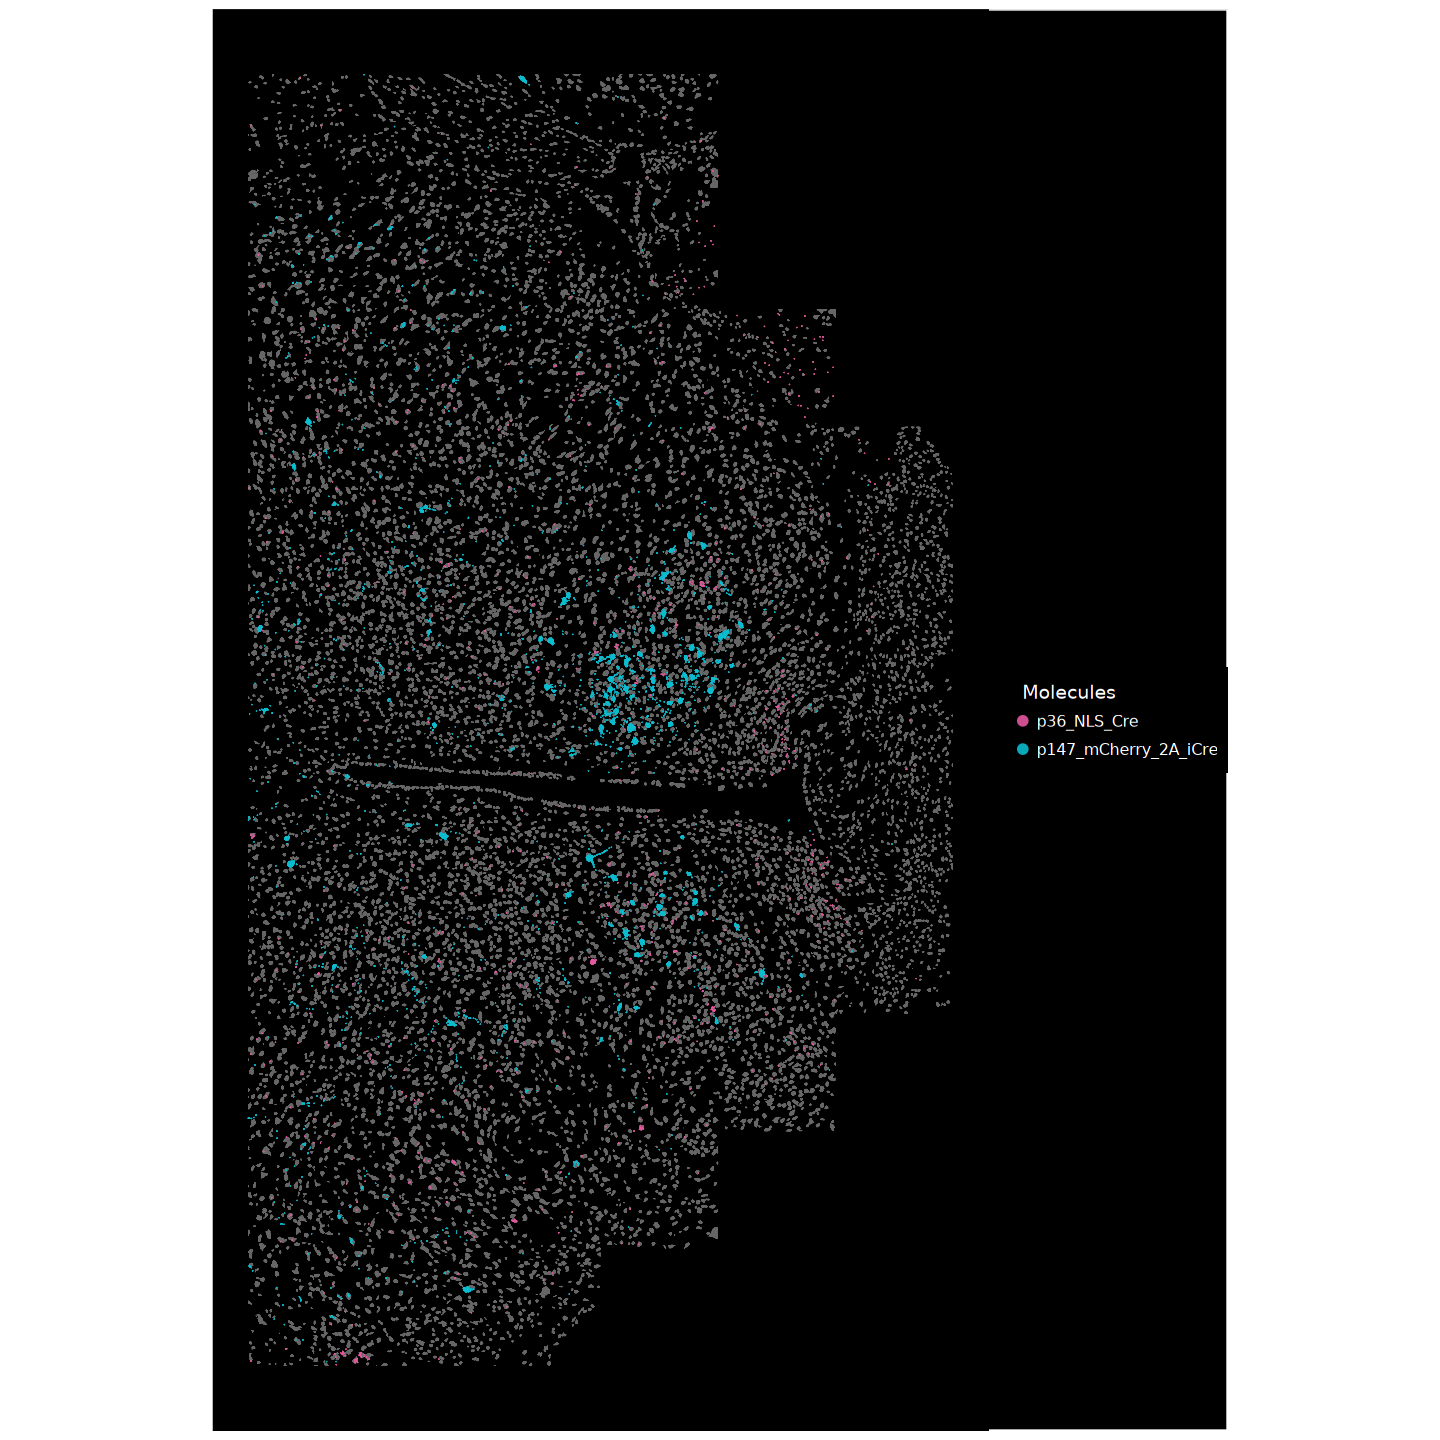

In [11]:
fov <- "S3B2"
seurat_merged$plot <- "Cell boundaries"
p <- ImageDimPlot(seurat_merged,
                  border.color = NA,
                  boundaries = "segmentation",
                  group.by = "plot",
                  cols = "#666666",
                  fov = fov,
                  molecules = c("p36_NLS_Cre", "p147_mCherry_2A_iCre"),
                  mols.cols = c("#e458a0", "#0cbbce"),
                  mols.size = 0.5,
                  mols.alpha = 0.9,
                  nmols = 10000,
                  dark.background = TRUE) +
  theme(panel.grid.major = element_blank(),
        panel.grid.minor = element_blank(),
        legend.key.size  = unit(0.5, "lines"),
        legend.text      = element_text(size = 9),
        plot.background  = element_rect(fill = "black"),
        panel.background = element_rect(fill = "black"),
        plot.margin      = unit(c(0, 0, 0, 0), "cm"))

# Overwrite shape to solid circle (16) on molecule layers
# Molecule layers are GeomPoint layers that are NOT the segmentation fill
for (i in seq_along(p$layers)) {
  if (inherits(p$layers[[i]]$geom, "GeomPoint")) {
    p$layers[[i]]$aes_params$shape  <- 16
    p$layers[[i]]$aes_params$stroke <- 0
  }
}

# Rasterize all non-text layers, keep text/legend vectorized
p_rast <- rasterise(p, layers = c("Point", "Polygon"), dpi = 600)
show(p_rast)
filename <- "Figure_2b.pdf"
ggsave(file.path(filename), plot = p_rast, width = 12, height = 12, bg = "transparent")

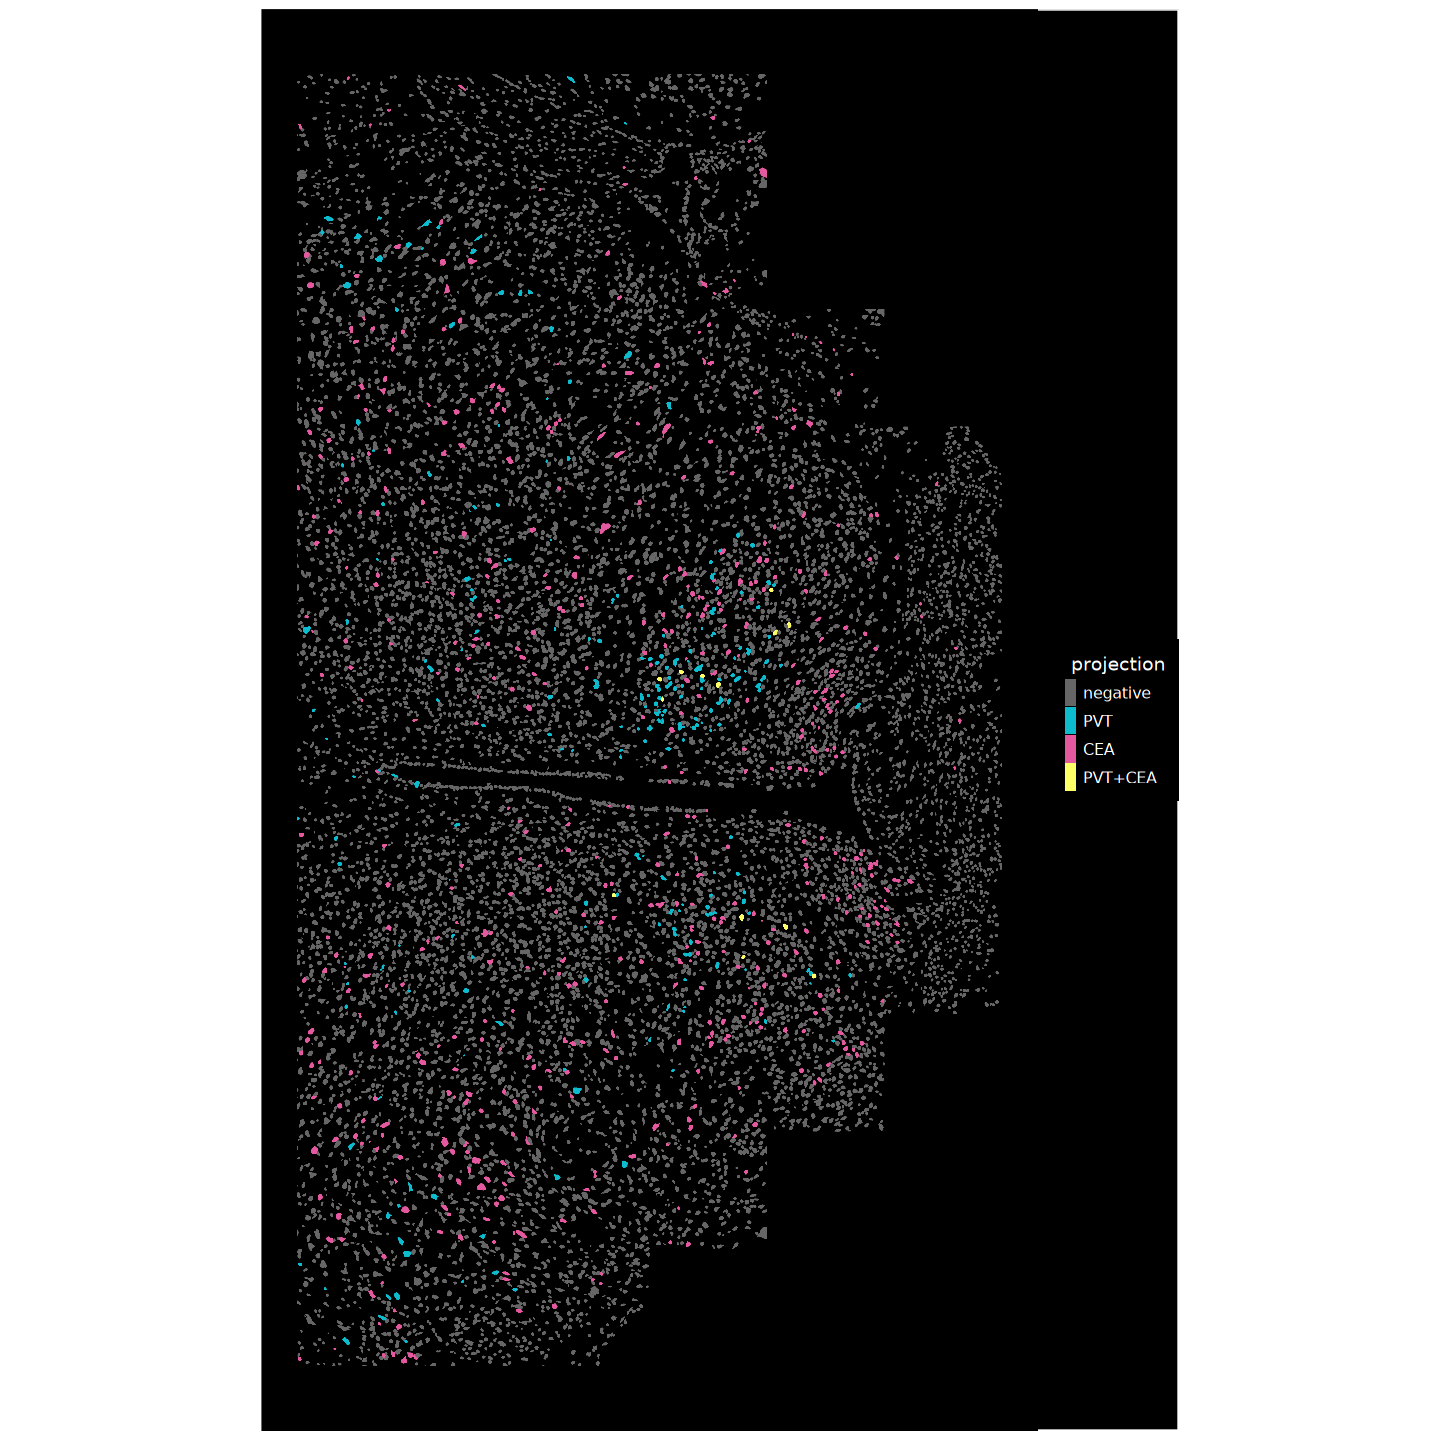

In [13]:
fov <- "S3B2"
cols <- c('#e458a0', '#0cbbce', '#ffff66', "#666666")
cells <- c("CEA", "PVT", "PVT+CEA", "negative")
names(cols) <- cells
p <- ImageDimPlot(seurat_merged,
                  border.color = NA,
                  boundaries = "segmentation",
                  group.by = "projection",
                  cols = cols,
                  fov = fov,
                  dark.background = TRUE) +
  theme(panel.grid.major = element_blank(),
        panel.grid.minor = element_blank(),
        legend.key.size  = unit(0.5, "lines"),
        legend.text      = element_text(size = 9),
        plot.background  = element_rect(fill = "black"),
        panel.background = element_rect(fill = "black"),
        plot.margin      = unit(c(0, 0, 0, 0), "cm"))

# Rasterize all non-text layers, keep text/legend vectorized
p_rast <- rasterise(p, layers = c("Point", "Polygon"), dpi = 600)
show(p_rast)
filename <- "Figure_2c.pdf"
ggsave(file.path(filename), plot = p_rast, width = 12, height = 12, bg = "transparent")

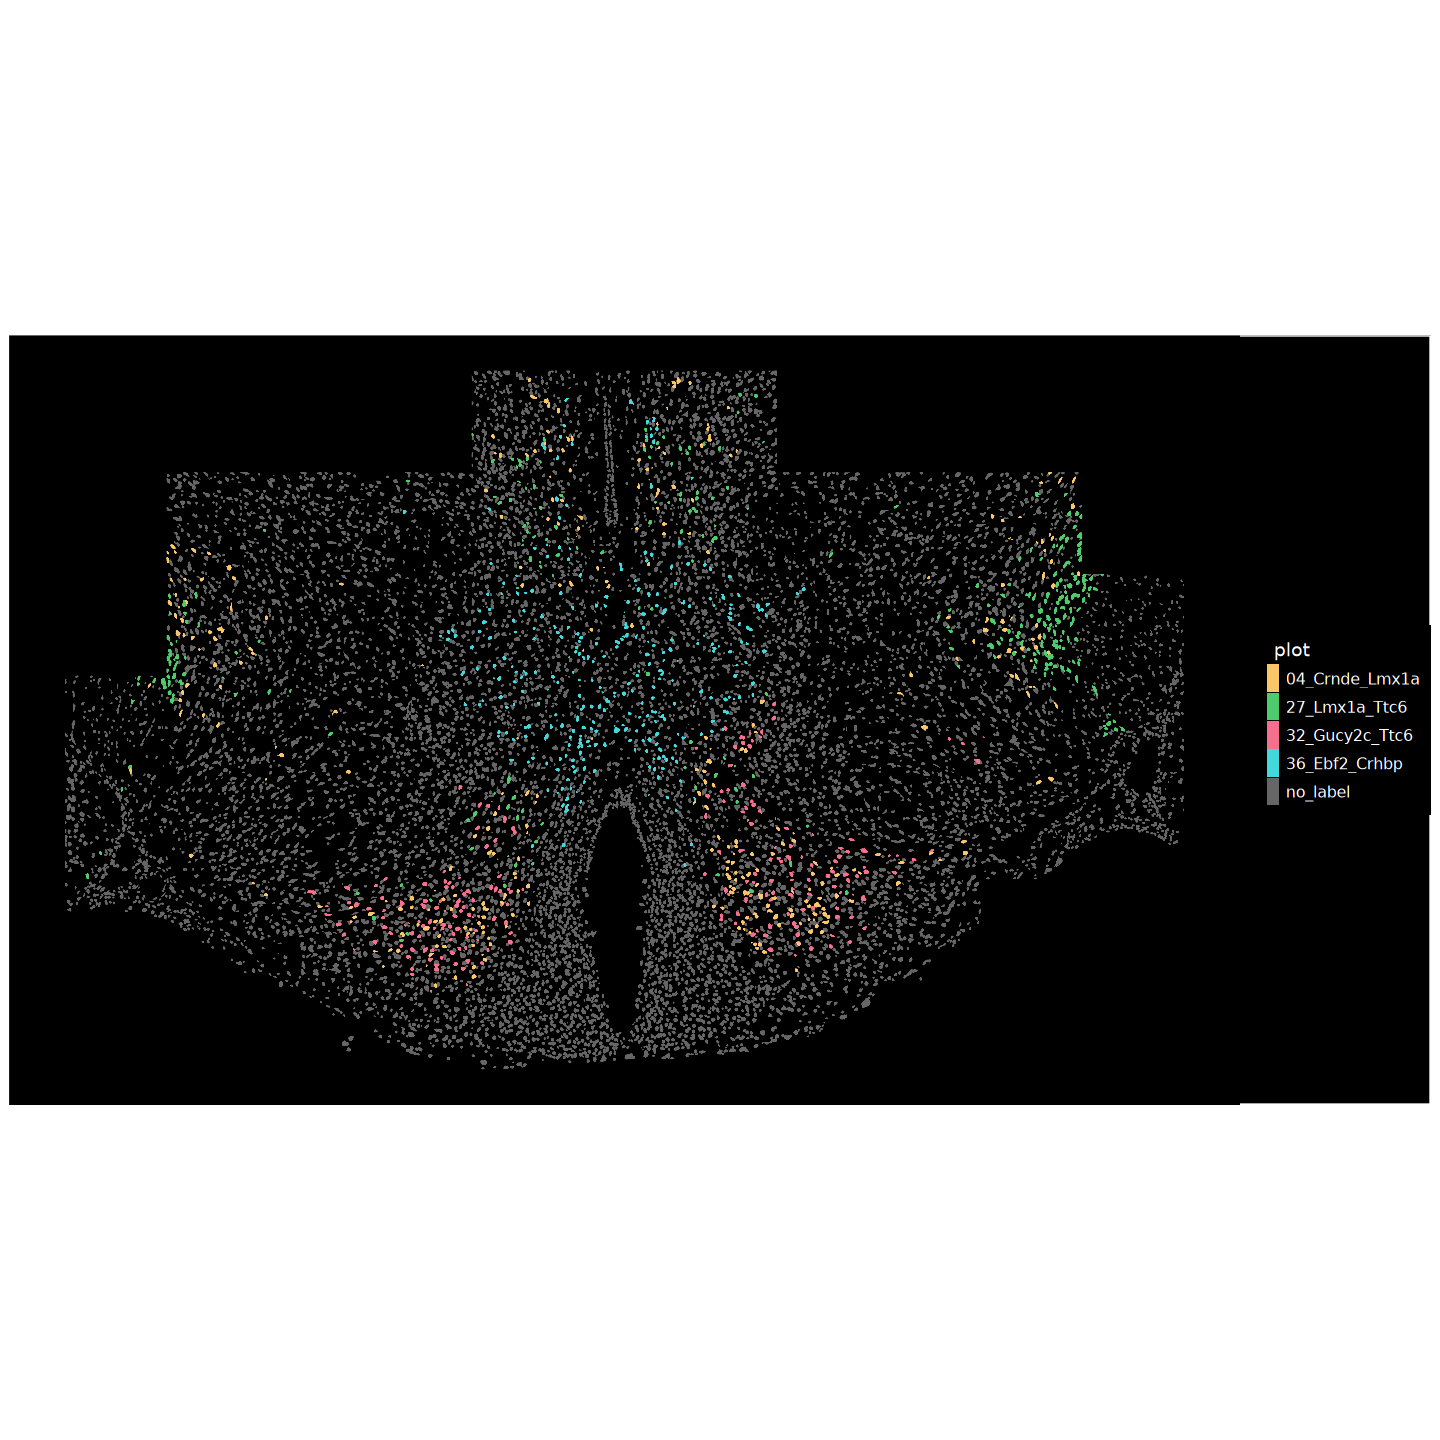

In [15]:
seurat_merged$detailed_celltype <- seurat_merged$detailed_celltype_annotation
seurat_merged@meta.data[["detailed_celltype"]] <- ifelse(seurat_merged@meta.data[["score_detailed_celltype_annotation"]] > 0.4, 
                                                         seurat_merged@meta.data[["detailed_celltype"]], "no_label")
glia <- c('04_Crnde_Lmx1a', '27_Lmx1a_Ttc6', '32_Gucy2c_Ttc6', '36_Ebf2_Crhbp')
seurat_merged$plot <- seurat_merged$detailed_celltype
seurat_merged@meta.data[["plot"]] <- ifelse(seurat_merged@meta.data[["plot"]] %in% glia, seurat_merged@meta.data[["plot"]], "no_label")

fov <- "S3C2"
cols <- c('#fbc668', '#4ecc6d', '#f56f8e', "#42d9dc","#666666")
cells <- c("04_Crnde_Lmx1a", "27_Lmx1a_Ttc6", "32_Gucy2c_Ttc6", "36_Ebf2_Crhbp", "no_label")
names(cols) <- cells
seurat_merged@meta.data[["plot"]] <- factor(
  seurat_merged@meta.data[["plot"]],
  levels = sort(unique(seurat_merged@meta.data[["plot"]]))
)

p <- ImageDimPlot(seurat_merged,
                  border.color = NA,
                  boundaries = "segmentation",
                  group.by = "plot",
                  cols = cols,
                  fov = fov,
                  dark.background = TRUE) +
  theme(panel.grid.major = element_blank(),
        panel.grid.minor = element_blank(),
        legend.key.size  = unit(0.5, "lines"),
        legend.text      = element_text(size = 9),
        plot.background  = element_rect(fill = "black"),
        panel.background = element_rect(fill = "black"),
        plot.margin      = unit(c(0, 0, 0, 0), "cm"))

# Rasterize all non-text layers, keep text/legend vectorized
p_rast <- rasterise(p, layers = "Polygon", dpi = 600)
show(p_rast)
ggsave("Figure_4c.pdf", plot = p_rast, width = 12, height = 12, bg = "transparent")

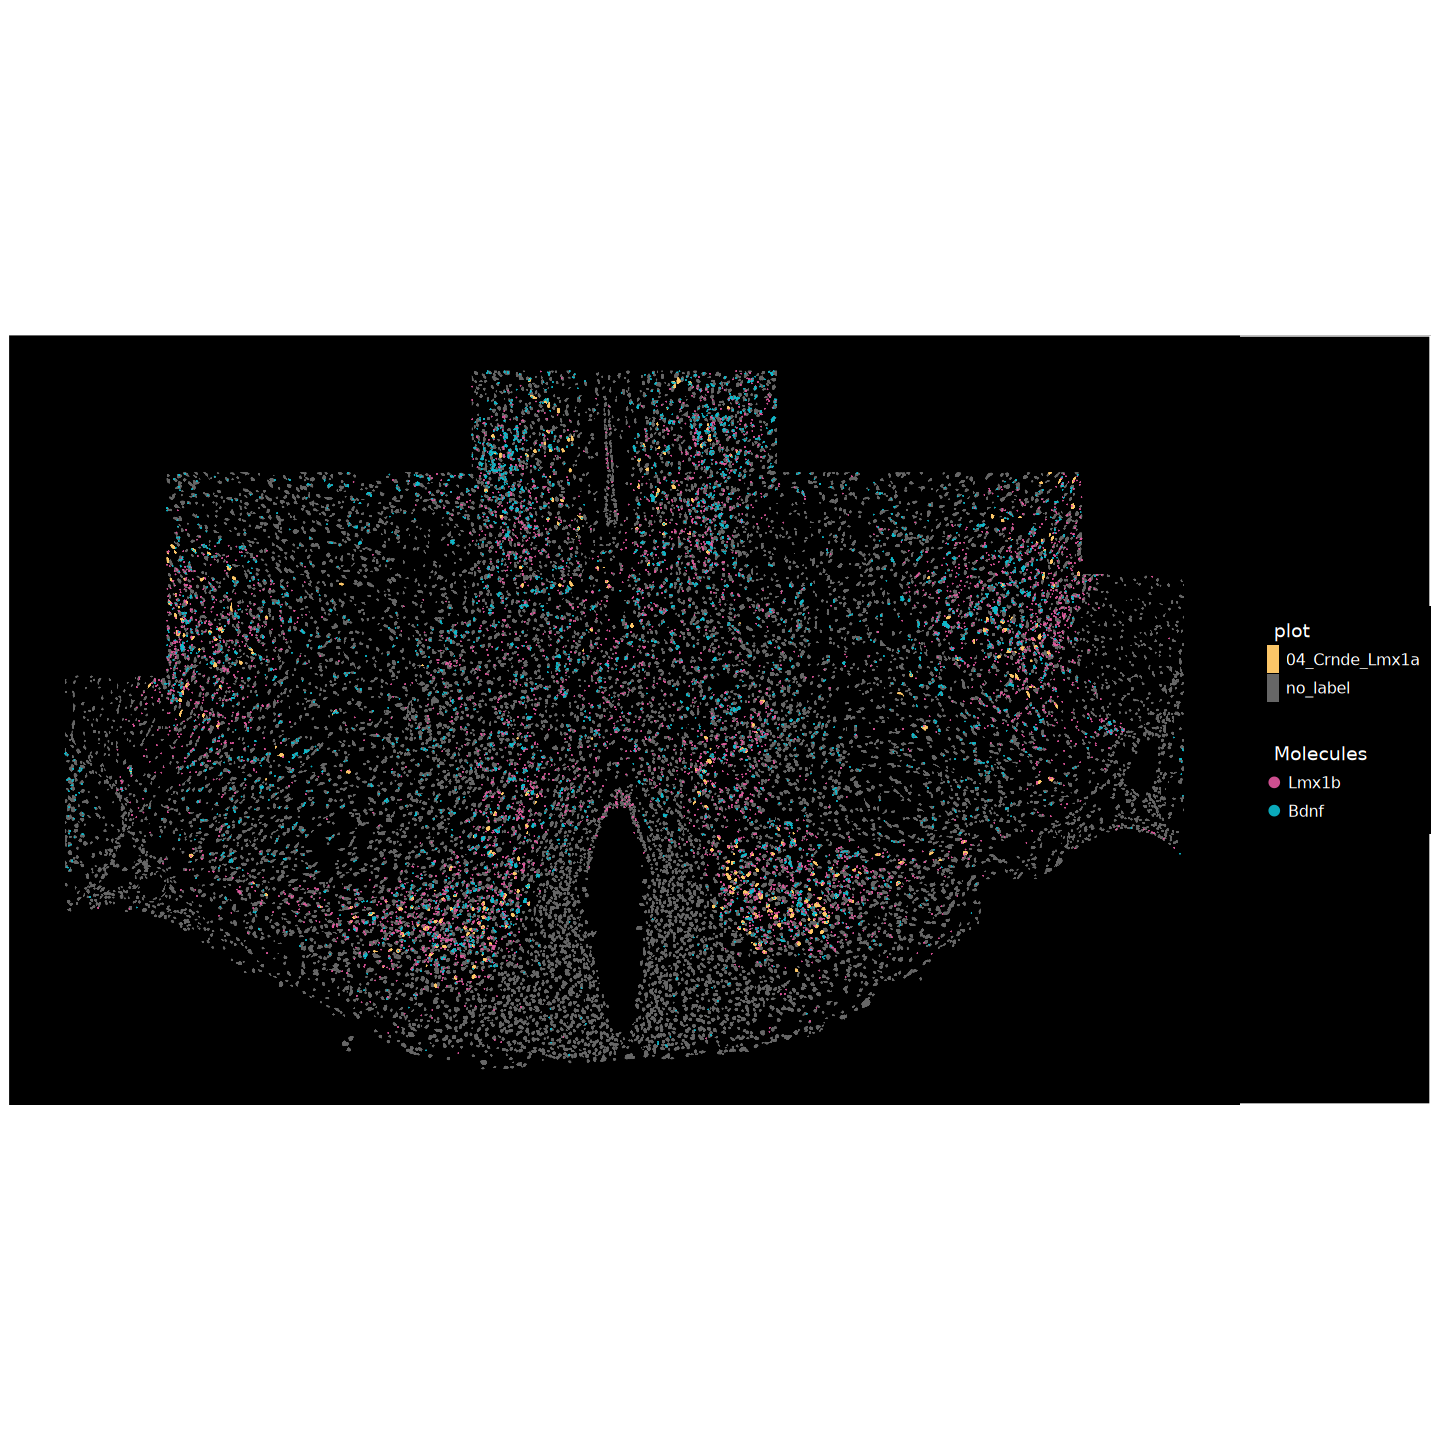

In [18]:
seurat_merged$detailed_celltype <- seurat_merged$detailed_celltype_annotation
seurat_merged@meta.data[["detailed_celltype"]] <- ifelse(seurat_merged@meta.data[["score_detailed_celltype_annotation"]] > 0.4, 
                                                         seurat_merged@meta.data[["detailed_celltype"]], "no_label")
glia <- c('04_Crnde_Lmx1a')
seurat_merged$plot <- seurat_merged$detailed_celltype
seurat_merged@meta.data[["plot"]] <- ifelse(seurat_merged@meta.data[["plot"]] %in% glia, seurat_merged@meta.data[["plot"]], "no_label")

fov <- "S3C2"
cols <- c('#fbc668', "#666666")
cells <- c("04_Crnde_Lmx1a", "no_label")
names(cols) <- cells
# Sort factor levels alphabetically
seurat_merged@meta.data[["plot"]] <- factor(
  seurat_merged@meta.data[["plot"]],
  levels = sort(unique(seurat_merged@meta.data[["plot"]]))
)

p <- ImageDimPlot(seurat_merged,
                  border.color = NA,
                  boundaries = "segmentation",
                  group.by = "plot",
                  cols = cols,
                  fov = fov,
                  molecules = c("Lmx1b", "Bdnf"),
                  mols.cols = c("#e458a0", "#0cbbce"),
                  mols.size = 0.5,
                  mols.alpha = 0.9,
                  nmols = 5000,
                  dark.background = TRUE) +
  theme(panel.grid.major = element_blank(),
        panel.grid.minor = element_blank(),
        legend.key.size  = unit(0.5, "lines"),
        legend.text      = element_text(size = 9),
        plot.background  = element_rect(fill = "black"),
        panel.background = element_rect(fill = "black"),
        plot.margin      = unit(c(0, 0, 0, 0), "cm"))

# Overwrite shape to solid circle (16) on molecule layers
# Molecule layers are GeomPoint layers that are NOT the segmentation fill
for (i in seq_along(p$layers)) {
  if (inherits(p$layers[[i]]$geom, "GeomPoint")) {
    p$layers[[i]]$aes_params$shape  <- 16
    p$layers[[i]]$aes_params$stroke <- 0
  }
}

# Rasterize all non-text layers, keep text/legend vectorized
p_rast <- rasterise(p, layers = c("Point", "Polygon"), dpi = 600)
show(p_rast)
filename <- "Figure_4h.pdf"
ggsave(file.path(filename), plot = p_rast, width = 12, height = 12, bg = "transparent")

Saving 6.67 x 6.67 in image


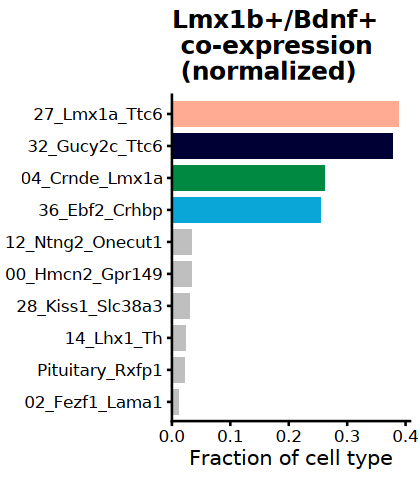

In [ ]:
counts <- GetAssayData(seurat_merged, assay = "raw", layer = "counts")
seurat_merged$Lepr_pos  <- counts["Lmx1b", ]  > 2
seurat_merged$Calcr_pos <- counts["Bdnf", ] > 2
seurat_merged$expr_class <- "Lmx1b-/Bdnf-"
seurat_merged$expr_class[seurat_merged$Lepr_pos]  <- "Lmx1b+/Bdnf-"
seurat_merged$expr_class[seurat_merged$Calcr_pos] <- "Lmx1b-/Bdnf+"
seurat_merged$expr_class[seurat_merged$Lepr_pos & seurat_merged$Calcr_pos] <- "Lmx1b+/Bdnf+"

lmx1a_types <- c('04_Crnde_Lmx1a', '27_Lmx1a_Ttc6', '32_Gucy2c_Ttc6', '36_Ebf2_Crhbp')

# Cell type totals for normalization
ct_totals <- seurat_merged@meta.data %>%
  filter(detailed_celltype != "no_label") %>%
  count(detailed_celltype, name = "n_total")

coexpr_summary <- seurat_merged@meta.data %>%
  filter(detailed_celltype != "no_label", expr_class == "Lmx1b+/Bdnf+") %>%
  count(detailed_celltype, name = "n_double_pos") %>%
  left_join(ct_totals, by = "detailed_celltype") %>%
  mutate(fraction = n_double_pos / n_total) %>%
  arrange(desc(fraction)) %>%
  mutate(
    bar_color = ifelse(detailed_celltype %in% lmx1a_types,
                       colors_detailed[detailed_celltype], "grey75")
  )

top10 <- coexpr_summary %>%
  slice_max(fraction, n = 10) %>%
  mutate(detailed_celltype = factor(detailed_celltype, levels = rev(detailed_celltype)))

bar_colors_top10 <- setNames(top10$bar_color, top10$detailed_celltype)

p <- ggplot(top10, aes(x = detailed_celltype, y = fraction, fill = detailed_celltype)) +
  geom_col(width = 0.8) +
  scale_fill_manual(values = bar_colors_top10, guide = "none") +
  scale_y_continuous(expand = expansion(mult = c(0, 0.05))) +
  coord_flip() +
  labs(title = "Lmx1b+/Bdnf+ \n co-expression \n (normalized)",
       x = NULL, y = "Fraction of cell type") +
  theme_classic(base_size = 12) +
  theme(plot.title = element_text(face = "bold"))

options(repr.plot.width = 3.5, repr.plot.height = 4)
print(p)
ggsave("coexpr_Lmx1b_Bdnf_top10_normalized.pdf", plot = p, bg = "transparent")

In [ ]:
seurat_merged$detailed_celltype <- seurat_merged$detailed_celltype_annotation
seurat_merged@meta.data[["detailed_celltype"]] <- ifelse(seurat_merged@meta.data[["score_detailed_celltype_annotation"]] > 0.4, 
                                                         seurat_merged@meta.data[["detailed_celltype"]], "no_label")
glia <- c('04_Crnde_Lmx1a', '27_Lmx1a_Ttc6', '32_Gucy2c_Ttc6', '36_Ebf2_Crhbp')
seurat_merged$plot <- seurat_merged$detailed_celltype
seurat_merged@meta.data[["plot"]] <- ifelse(seurat_merged@meta.data[["plot"]] %in% glia, "Lmx1a+", "Lmx1a-")

p <- ImageDimPlot(seurat_merged,
                  border.color = NA,
                  boundaries = "segmentation",
                  group.by = "plot",
                  cols = c("#666666", "#ef4224"),
                  fov = "S2C2",
                  dark.background = TRUE) +
  theme(panel.grid.major = element_blank(),
        panel.grid.minor = element_blank(),
        legend.key.size  = unit(0.5, "lines"),
        legend.text      = element_text(size = 9),
        plot.background  = element_rect(fill = "black"),
        panel.background = element_rect(fill = "black"),
        plot.margin      = unit(c(0, 0, 0, 0), "cm"))

# Rasterize all non-text layers, keep text/legend vectorized
p_rast <- rasterise(p, layers = "Polygon", dpi = 600)
show(p_rast)
ggsave("Figure_6b.pdf", plot = p_rast, width = 12, height = 12, bg = "transparent")

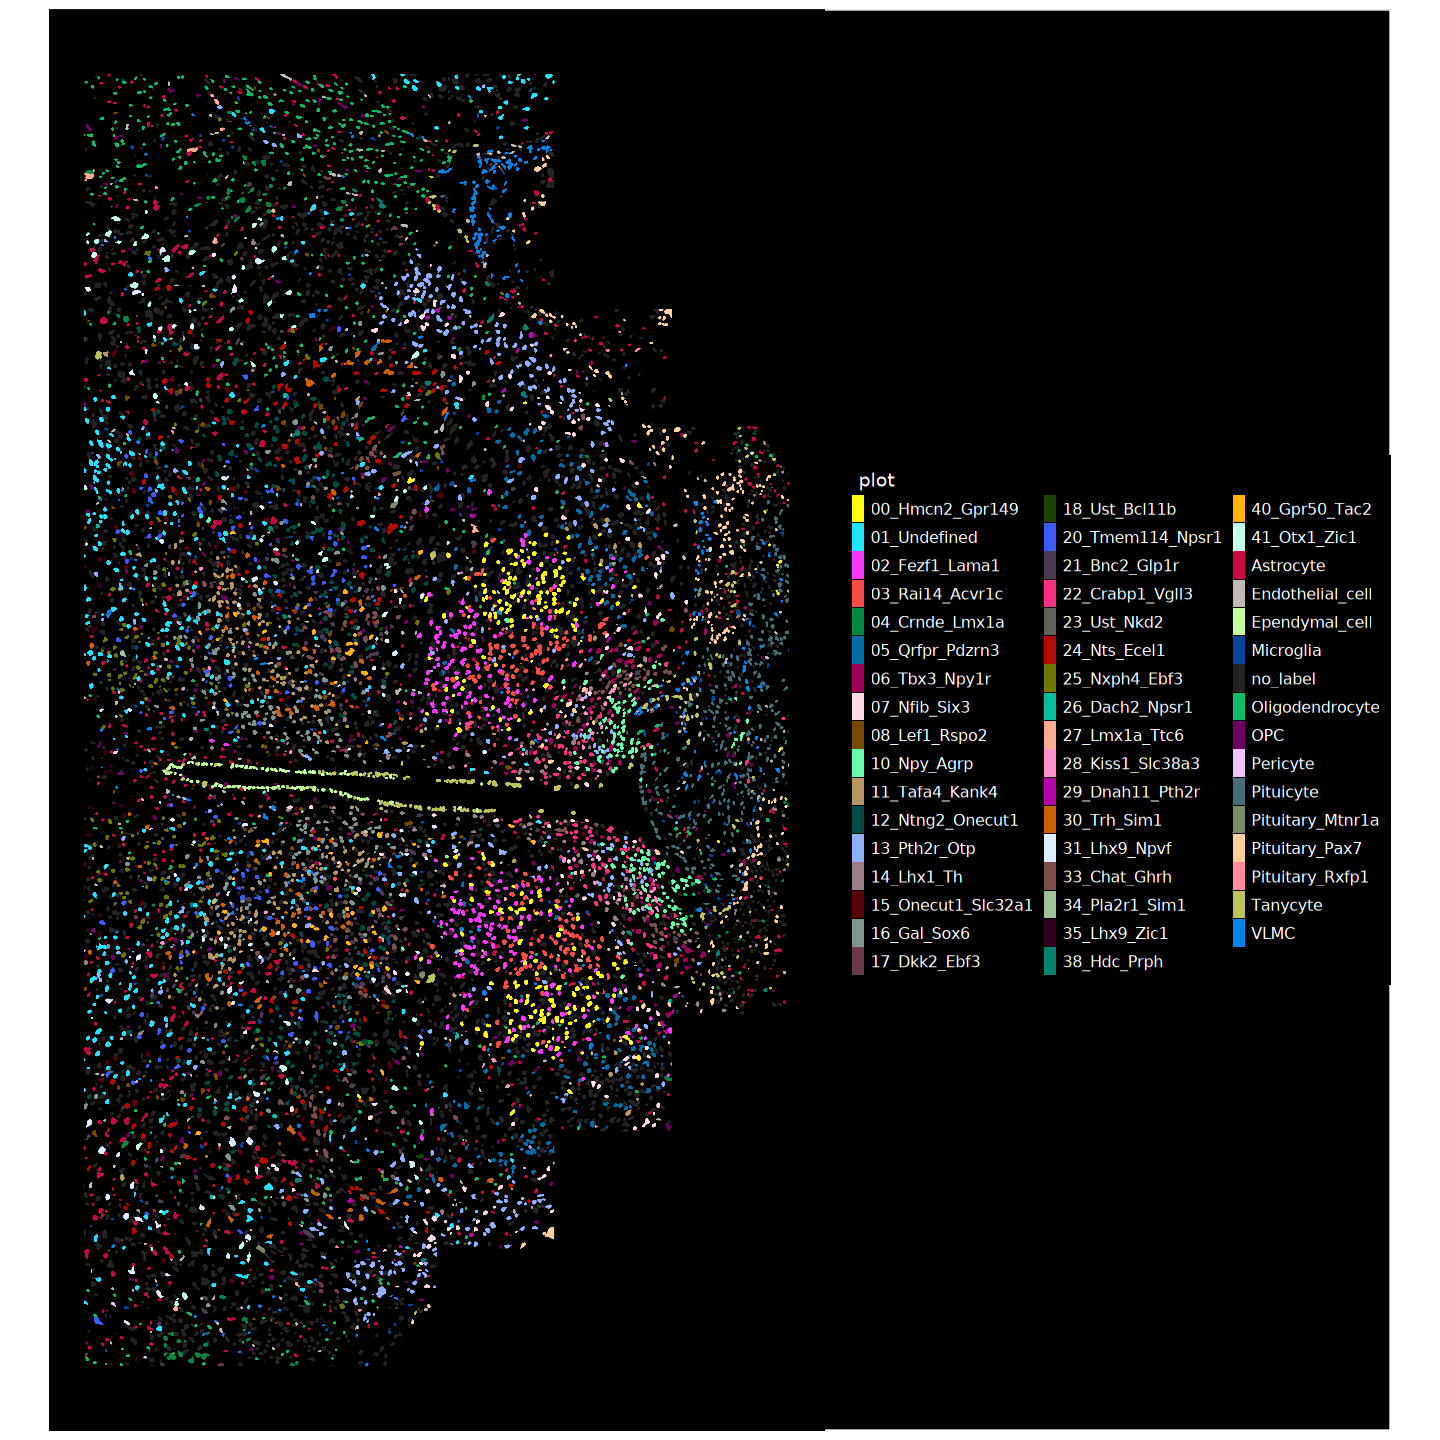

In [7]:
seurat_merged$detailed_celltype <- seurat_merged$detailed_celltype_annotation
seurat_merged@meta.data[["detailed_celltype"]] <- ifelse(seurat_merged@meta.data[["score_detailed_celltype_annotation"]] > 0.4, 
                                                         seurat_merged@meta.data[["detailed_celltype"]], "no_label")

fov <- "S3B2"
seurat_merged@meta.data[["plot"]] <- factor(
  seurat_merged@meta.data[["plot"]],
  levels = sort(unique(seurat_merged@meta.data[["plot"]]))
)

p <- ImageDimPlot(seurat_merged,
                  border.color = NA,
                  boundaries = "segmentation",
                  group.by = "plot",
                  cols = colors_detailed,
                  fov = fov,
                  dark.background = TRUE) +
  theme(panel.grid.major = element_blank(),
        panel.grid.minor = element_blank(),
        legend.key.size  = unit(0.5, "lines"),
        legend.text      = element_text(size = 9),
        plot.background  = element_rect(fill = "black"),
        panel.background = element_rect(fill = "black"),
        plot.margin      = unit(c(0, 0, 0, 0), "cm"))

# Rasterize all non-text layers, keep text/legend vectorized
p_rast <- rasterise(p, layers = "Polygon", dpi = 600)
show(p_rast)
ggsave("Supplementary_Figure_2b.pdf", plot = p_rast, width = 12, height = 12, bg = "transparent")